# Segmentación de Clientes

## Proyecto: SaaS Customer Churn Intelligence

A continuación agruparemos clientes con características similares para entender perfiles de contratación, antigüedad, servicios y facturación. La segmentación complementa al modelo predictivo: no sustituye el riesgo de churn, sino que aporta contexto para decidir cómo actuar.

Esta segmentación de los datos nos permitirá conocer **qué tipos de clientes existen dentro de la cartera**.

`Churn` se utilizará únicamente para describir los segmentos después del clustering. `customerID` se conservará para identificar clientes, pero ninguno de los dos participará en la creación de los clusters.

## 1. Carga de los datos

Partimos de `../data/processed/features.parquet`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

DATA_PATH = "../data/processed/features.parquet"
OUTPUT_PATH = "../data/processed/customer_segments.parquet"

df = pd.read_parquet(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
print("\nColumnas:")
print(df.columns.tolist())

Shape: (7043, 29)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,monthly_charge_group,is_monthly_contract,num_services_contracted,has_tech_support,has_online_security,uses_electronic_check,churn_target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months,Low,1,1,0,0,1,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 months,Medium,0,2,0,1,0,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months,Medium,1,2,0,1,0,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months,Low,0,3,1,1,0,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months,Medium,1,0,0,0,1,1



Columnas:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'tenure_group', 'monthly_charge_group', 'is_monthly_contract', 'num_services_contracted', 'has_tech_support', 'has_online_security', 'uses_electronic_check', 'churn_target']


In [2]:
print("Tipos de datos:")
display(df.dtypes.to_frame("dtype"))
print("Valores nulos por columna:")
display(df.isna().sum().sort_values(ascending=False).head(15))

Tipos de datos:


,dtype
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Valores nulos por columna:


TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
Dependents           0
TechSupport          0
StreamingTV          0
dtype: int64

## 2. Selección de variables


| Variable | Motivo |
|---|---|
| `tenure` | Representa la antigüedad del cliente. |
| `MonthlyCharges` | Gasto mensual. |
| `Contract` | Diferencia el tipo de contratación. |
| `InternetService` | Tipo de servicio principal. |
| `num_services_contracted` | Adopción de servicios adicionales. |
| `PaymentMethod` | Forma de pago. |

No utilizaremos `Churn` para crear los segmentos, ya que después queremos analizar el churn de cada grupo.

Tampoco utilizaremos `TotalCharges` porque está muy relacionada con `tenure` y `MonthlyCharges`, y podría dar más peso del necesario a la información de facturación. Las variables derivadas que representan información ya incluida en las variables seleccionadas tampoco se utilizarán.

In [3]:
segment_features = [
    "tenure", "MonthlyCharges", "Contract", "InternetService",
    "num_services_contracted", "PaymentMethod"
]
required_columns = ["customerID", "Churn"] + segment_features
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Faltan columnas necesarias: {missing_columns}")

segmentation_df = df[segment_features].copy()
print("Variables seleccionadas:", segment_features)
print("Valores nulos:")
display(segmentation_df.isna().sum())
if segmentation_df.isna().sum().sum() > 0:
    raise ValueError("Hay valores nulos en las variables seleccionadas para K-Means.")

Variables seleccionadas: ['tenure', 'MonthlyCharges', 'Contract', 'InternetService', 'num_services_contracted', 'PaymentMethod']
Valores nulos:


tenure                     0
MonthlyCharges             0
Contract                   0
InternetService            0
num_services_contracted    0
PaymentMethod              0
dtype: int64

## 3. Preparación de las variables

K-Means utiliza distancias entre clientes. Por eso, primero convertimos las variables categóricas a variables numéricas y después estandarizamos todas las variables.

De esta forma evitamos que una variable numérica con una escala mayor domine el cálculo de las distancias.

In [4]:
from sklearn.preprocessing import StandardScaler

categorical_columns = segmentation_df.select_dtypes(include=["str", "category", "bool"]).columns.tolist()
numeric_columns = segmentation_df.select_dtypes(include=["number"]).columns.tolist()

segmentation_encoded = pd.get_dummies(
    segmentation_df,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

scaler = StandardScaler()
X_segmentation = scaler.fit_transform(segmentation_encoded)

print("Variables numéricas:", numeric_columns)
print("Variables categóricas:", categorical_columns)
print("Shape después del encoding:", segmentation_encoded.shape)
print("Shape final para K-Means:", X_segmentation.shape)
print("NaN:", np.isnan(X_segmentation).sum(), "| Infinitos:", np.isinf(X_segmentation).sum())

Variables numéricas: ['tenure', 'MonthlyCharges', 'num_services_contracted']
Variables categóricas: ['Contract', 'InternetService', 'PaymentMethod']
Shape después del encoding: (7043, 13)
Shape final para K-Means: (7043, 13)
NaN: 0 | Infinitos: 0


## 4. Primer modelo de segmentación: K-Means

Utilizaremos **K-Means**, un algoritmo sencillo que permite agrupar clientes según la similitud de sus características.

Probaremos varios valores de `K` para decidir cuántos segmentos tienen sentido en este proyecto.

In [5]:
from sklearn.cluster import KMeans

k_values = [2, 3, 4, 5, 6]
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_segmentation)
    inertias.append(model.inertia_)

elbow_results = pd.DataFrame({"k": k_values, "inertia": inertias})
display(elbow_results)

,k,inertia
0,2,73037.804175
1,3,58595.702987
2,4,50223.563232
3,5,43645.713887
4,6,39985.384485


## 5. Selección del número de segmentos

Para elegir el número de segmentos utilizamos el **método del codo**. La inercia disminuye al aumentar `K`, pero llega un momento en el que añadir más grupos aporta una mejora menor.

Además del resultado técnico, tendremos en cuenta que los segmentos sean suficientemente grandes y fáciles de interpretar desde el punto de vista de negocio.

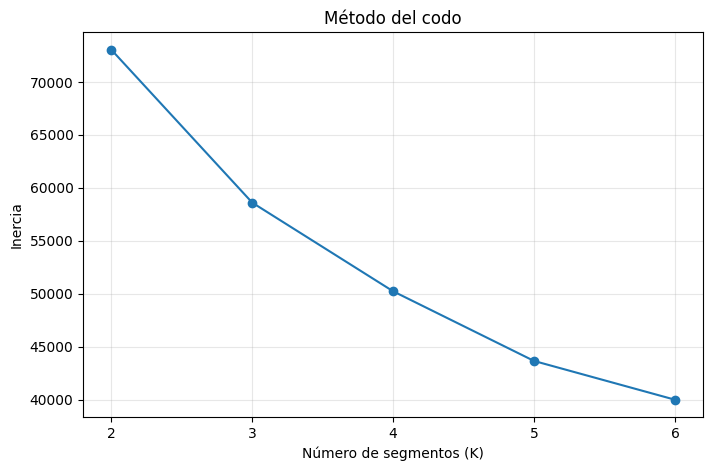

Resultados de la selección:


,k,inertia
0,2,73037.804
1,3,58595.703
2,4,50223.563
3,5,43645.714
4,6,39985.384


K seleccionado: 4
La elección busca un equilibrio entre el resultado del codo y la facilidad de interpretar los segmentos.


In [6]:
plt.figure(figsize=(8, 5))
plt.plot(elbow_results["k"], elbow_results["inertia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de segmentos (K)")
plt.ylabel("Inercia")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()

print("Resultados de la selección:")
display(elbow_results.round(3))

# A partir de la gráfica y de los resultados, elegimos 4 segmentos.
selected_k = 4
print("K seleccionado:", selected_k)
print("La elección busca un equilibrio entre el resultado del codo y la facilidad de interpretar los segmentos.")

## 6. Creación de los segmentos finales

Entrenamos K-Means con el `K=4` seleccionado y asignamos a cada cliente un identificador técnico `segment`. No se elimina ningún cliente.

In [7]:
kmeans_final = KMeans(n_clusters=selected_k, random_state=42, n_init=10)
kmeans_final.fit(X_segmentation)

df_segmented = df.copy()
df_segmented["segment"] = kmeans_final.labels_

segment_sizes = df_segmented["segment"].value_counts().sort_index().to_frame("customer_count")
segment_sizes["customer_percentage"] = segment_sizes["customer_count"] / len(df_segmented) * 100

display(segment_sizes.round(2))
print("Clientes sin segmento:", df_segmented["segment"].isna().sum())
print("Segmentos vacíos:", set(range(selected_k)) - set(df_segmented["segment"].unique()))

,customer_count,customer_percentage
segment,,
0,1993,28.30
1,2155,30.60
2,1526,21.67
3,1369,19.44


Clientes sin segmento: 0
Segmentos vacíos: set()


## 7. Perfilado de los segmentos

Esta es una de las partes principales del análisis. Vamos a comparar los segmentos utilizando antigüedad, gasto, servicios, tipo de contrato, servicio de Internet y método de pago.

Primero observamos los valores numéricos y después la distribución de las variables categóricas. Las diferencias observadas sirven para describir los grupos, pero no implican causalidad.

In [8]:
segment_numeric_summary = (
    df_segmented.groupby("segment")[[
        "tenure", "MonthlyCharges", "TotalCharges", "num_services_contracted"
    ]].agg(["mean", "median"]).round(2)
)
display(segment_numeric_summary)

tenure        MonthlyCharges        TotalCharges           \
          mean median           mean median         mean   median   
segment                                                             
0        56.40   61.0          84.15  85.35      4842.10  4871.45   
1        21.60   16.0          87.02  86.00      1971.23  1422.10   
2        30.55   25.0          21.08  20.15       665.22   523.67   
3        16.38   11.0          50.19  50.30       852.42   563.58   

        num_services_contracted         
                           mean median  
segment                                 
0                          4.01    4.0  
1                          1.91    2.0  
2                          0.00    0.0  
3                          1.64    2.0

In [9]:
def category_distribution(data, column):
    return (pd.crosstab(data["segment"], data[column], normalize="index") * 100).round(1)

print("Contract (%):")
display(category_distribution(df_segmented, "Contract"))
print("InternetService (%):")
display(category_distribution(df_segmented, "InternetService"))
print("PaymentMethod (%):")
display(category_distribution(df_segmented, "PaymentMethod"))

Contract (%):


Contract,Month-to-month,One year,Two year
segment,,,
0,0.2,48.1,51.7
1,98.7,1.2,0.1
2,34.3,23.9,41.8
3,89.2,9.1,1.8


InternetService (%):


InternetService,DSL,Fiber optic,No
segment,,,
0,52.8,47.2,0.0
1,0.0,100.0,0.0
2,0.0,0.0,100.0
3,100.0,0.0,0.0


PaymentMethod (%):


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
segment,,,,
0,34.3,35.4,20.2,10.0
1,15.2,13.5,61.9,9.4
2,21.8,21.7,8.0,48.6
3,14.7,14.1,37.0,34.3


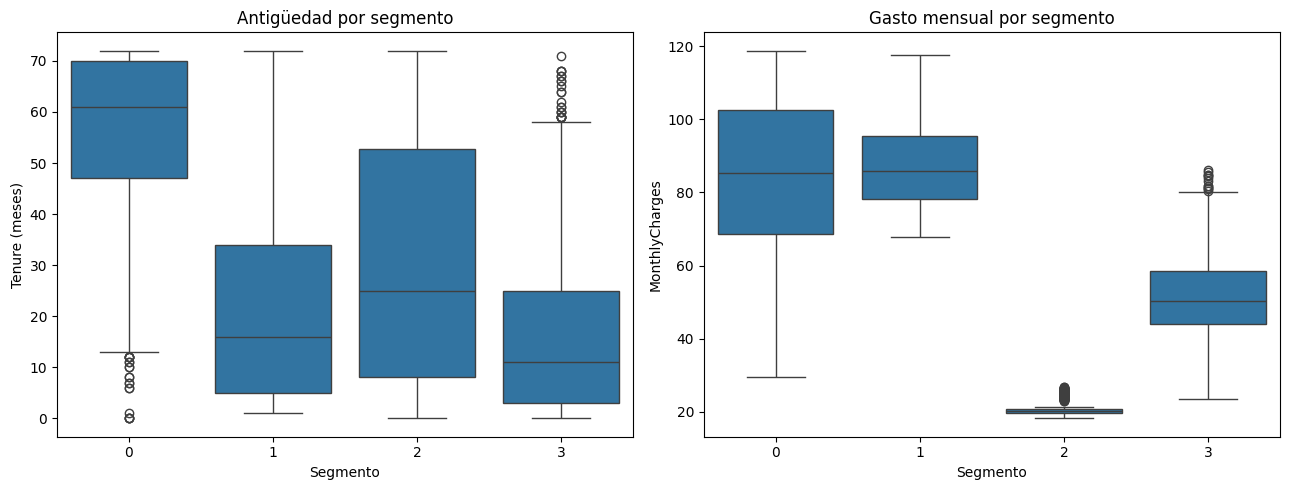

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df_segmented, x="segment", y="tenure", ax=axes[0])
axes[0].set_title("Antigüedad por segmento")
axes[0].set_xlabel("Segmento")
axes[0].set_ylabel("Tenure (meses)")
sns.boxplot(data=df_segmented, x="segment", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Gasto mensual por segmento")
axes[1].set_xlabel("Segmento")
axes[1].set_ylabel("MonthlyCharges")
plt.tight_layout()
plt.show()

## Lectura del perfilado de los segmentos

| Segmento | Perfil principal |
|:---:|---|
| **0** | 🟢 **Clientes de larga duración** · Contratos de 1-2 años · DSL/Fibra · Pago automático |
| **1** | 🔵 **Mensuales con fibra** · 98,7 % contrato mensual · 100 % fibra · 61,9 % cheque electrónico |
| **2** | 🟠 **Sin Internet** · 100 % sin Internet · Mayor presencia de contratos de 2 años · 48,6 % mailed check |
| **3** | 🟣 **Mensuales con DSL** · 89,2 % contrato mensual · 100 % DSL · Predominio de pagos por cheque |

### Diferencias principales

- **Contrato:** Segmentos **1 y 3** → principalmente mensuales. Segmento **0** → contratos de mayor duración.
- **Internet:** Segmento **1** → fibra · Segmento **3** → DSL · Segmento **2** → sin Internet.
- **Pago:** Segmento **1** → destaca el cheque electrónico · Segmento **2** → destaca el cheque enviado por correo.
- **Segmento 0** presenta una distribución de pagos más equilibrada.

> Los segmentos son **descriptivos**: estas diferencias permiten caracterizar los perfiles, pero no implican causalidad.

## 8. Churn por segmento

Ahora utilizamos `Churn` para comprobar si los segmentos presentan diferentes niveles de abandono.

El churn no se utilizó para crear los clusters, por lo que esta comparación nos permite conectar la segmentación con el objetivo principal del proyecto.

,churn_rate,customer_count
segment,,
1,54.25,2155
3,29.66,1369
0,9.08,1993
2,7.40,1526


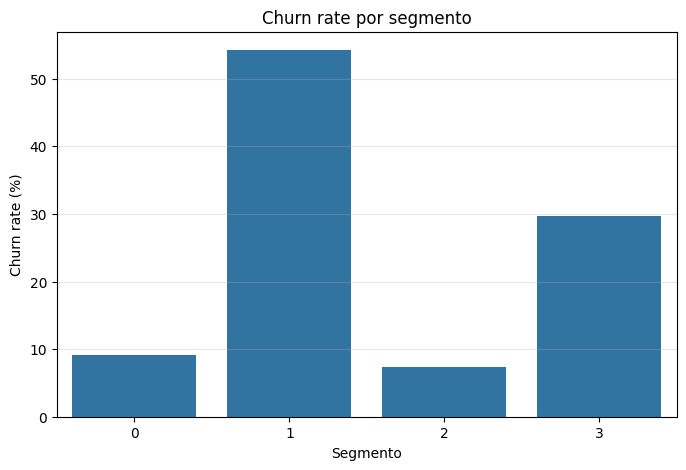

Hecho observado: segmento 1 tiene el mayor churn (54.2%).
Hecho observado: segmento 2 tiene el menor churn (7.4%).
Interpretación: los segmentos muestran distintos niveles de churn observado.
Hipótesis: las características de los segmentos con mayor churn pueden orientar futuras investigaciones de retención.


In [11]:
churn_by_segment = df_segmented.groupby("segment")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).to_frame("churn_rate")
churn_by_segment["customer_count"] = df_segmented["segment"].value_counts()
churn_by_segment = churn_by_segment.sort_values("churn_rate", ascending=False)
display(churn_by_segment.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(data=churn_by_segment.reset_index(), x="segment", y="churn_rate")
plt.title("Churn rate por segmento")
plt.xlabel("Segmento")
plt.ylabel("Churn rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.show()

highest = int(churn_by_segment["churn_rate"].idxmax())
lowest = int(churn_by_segment["churn_rate"].idxmin())
print(f"Hecho observado: segmento {highest} tiene el mayor churn ({churn_by_segment.loc[highest, 'churn_rate']:.1f}%).")
print(f"Hecho observado: segmento {lowest} tiene el menor churn ({churn_by_segment.loc[lowest, 'churn_rate']:.1f}%).")
print("Interpretación: los segmentos muestran distintos niveles de churn observado.")
print("Hipótesis: las características de los segmentos con mayor churn pueden orientar futuras investigaciones de retención.")

## 9. Segmentación orientada a riesgo y valor

Además del churn, podemos tener en cuenta el tamaño del segmento y el gasto mensual medio para valorar qué grupos pueden ser más relevantes.

No se trata de una puntuación de riesgo del modelo de churn, sino de una forma sencilla de interpretar la importancia de cada segmento para el negocio.

In [12]:
summary = df_segmented.groupby("segment").agg(
    customer_count=("customerID", "count"),
    customer_percentage=("customerID", lambda x: len(x) / len(df_segmented) * 100),
    average_tenure=("tenure", "mean"),
    average_monthly_charges=("MonthlyCharges", "mean"),
    average_total_charges=("TotalCharges", "mean"),
    average_services=("num_services_contracted", "mean"),
    churn_rate=("Churn", lambda x: (x == "Yes").mean() * 100)
).round(2)

display(summary.sort_values("churn_rate", ascending=False))

,customer_count,customer_percentage,average_tenure,average_monthly_charges,average_total_charges,average_services,churn_rate
segment,,,,,,,
1,2155,30.60,21.60,87.02,1971.23,1.91,54.25
3,1369,19.44,16.38,50.19,852.42,1.64,29.66
0,1993,28.30,56.40,84.15,4842.10,4.01,9.08
2,1526,21.67,30.55,21.08,665.22,0.00,7.40


## 10. Interpretación y nombre de los segmentos

Los números asignados por K-Means no tienen significado de negocio. Una vez revisados los perfiles y el churn observado, asignamos nombres sencillos que ayuden a comunicar las diferencias entre los grupos.

Los nombres son descriptivos y no representan causalidad.

In [13]:
segment_names = {
    0: "Clientes consolidados",
    1: "Clientes mensuales de alto riesgo",
    2: "Clientes de bajo gasto y baja adopción",
    3: "Clientes recientes con DSL"
}

named_summary = summary.copy()
named_summary.insert(0, "segment_name", named_summary.index.map(segment_names))
display(named_summary)

,segment_name,customer_count,customer_percentage,average_tenure,average_monthly_charges,average_total_charges,average_services,churn_rate
segment,,,,,,,,
0,Clientes consolidados,1993,28.30,56.40,84.15,4842.10,4.01,9.08
1,Clientes mensuales de alto riesgo,2155,30.60,21.60,87.02,1971.23,1.91,54.25
2,Clientes de bajo gasto y baja adopción,1526,21.67,30.55,21.08,665.22,0.00,7.40
3,Clientes recientes con DSL,1369,19.44,16.38,50.19,852.42,1.64,29.66


### Perfil y posible actuación
Las siguientes acciones son propuestas iniciales basadas en el perfil y el churn observado. No sustituyen al modelo individual de churn ni significan que todos los clientes de un segmento deban recibir la misma acción.

In [14]:
segment_actions = named_summary[[
    "customer_count", "churn_rate", "average_monthly_charges"
]].copy()
segment_actions.insert(0, "segment_name", segment_actions.index.map(segment_names))

actions = {
    0: "Mantener seguimiento y trabajar la fidelización.",
    1: "Priorizar seguimiento preventivo y revisar señales de riesgo.",
    2: "Revisar adopción de servicios y mantener seguimiento.",
    3: "Reforzar onboarding y activación temprana."
}

segment_actions["customer_success_action"] = segment_actions.index.map(actions)
display(segment_actions.round(2))

,segment_name,customer_count,churn_rate,average_monthly_charges,customer_success_action
segment,,,,,
0,Clientes consolidados,1993,9.08,84.15,Mantener seguimiento y trabajar la fidelización.
1,Clientes mensuales de alto riesgo,2155,54.25,87.02,Priorizar seguimiento preventivo y revisar señ...
2,Clientes de bajo gasto y baja adopción,1526,7.40,21.08,Revisar adopción de servicios y mantener segui...
3,Clientes recientes con DSL,1369,29.66,50.19,Reforzar onboarding y activación temprana.


## Interpretación de los segmentos

Los nombres se han asignado después de revisar las características de cada grupo:

- **Segmento 0 — Clientes consolidados:** son los clientes con mayor antigüedad, mayor número de servicios y una facturación acumulada elevada. Su churn observado es bajo.
- **Segmento 1 — Clientes mensuales de alto riesgo:** concentran el mayor churn observado (54,25 %) y tienen un gasto mensual medio de 87,02. La mayoría tiene contrato mensual y fibra óptica.
- **Segmento 2 — Clientes de bajo gasto y baja adopción:** no tienen servicio de Internet ni servicios adicionales y presentan el churn más bajo (7,40 %).
- **Segmento 3 — Clientes recientes con DSL:** presentan la menor antigüedad media y un churn del 29,66 %. La mayoría tiene contrato mensual y servicio DSL.

Estos nombres resumen los datos observados y se pueden utilizar para facilitar la comunicación con negocio.

## 11. Priorización de segmentos

La prioridad no se decide solo por churn. Un grupo con churn elevado puede ser pequeño, mientras que otro con churn algo menor puede concentrar muchos clientes y un gasto mensual mayor.

Usaremos un índice descriptivo sencillo que combina **riesgo observado, tamaño y gasto mensual**. No es una probabilidad ni una métrica financiera.

In [15]:
priority = named_summary[[
    "customer_count", "customer_percentage", "average_tenure",
    "average_monthly_charges", "churn_rate"
]].copy()
priority.insert(0, "segment_name", priority.index.map(segment_names))

priority["business_priority"] = "Prioridad media"
priority.loc[1, "business_priority"] = "Prioridad alta"
priority.loc[2, "business_priority"] = "Prioridad baja"

priority = priority.sort_values("churn_rate", ascending=False)
display(priority.round(2))

,segment_name,customer_count,customer_percentage,average_tenure,average_monthly_charges,churn_rate,business_priority
segment,,,,,,,
1,Clientes mensuales de alto riesgo,2155,30.60,21.60,87.02,54.25,Prioridad alta
3,Clientes recientes con DSL,1369,19.44,16.38,50.19,29.66,Prioridad media
0,Clientes consolidados,1993,28.30,56.40,84.15,9.08,Prioridad media
2,Clientes de bajo gasto y baja adopción,1526,21.67,30.55,21.08,7.40,Prioridad baja


In [16]:
print("Segmentos con prioridad alta:")
for segment, row in priority[priority["business_priority"] == "Prioridad alta"].iterrows():
    print(
        f"- Segmento {segment} ({row['segment_name']}): "
        f"{int(row['customer_count'])} clientes, "
        f"{row['churn_rate']:.1f}% churn y "
        f"{row['average_monthly_charges']:.2f} de gasto mensual medio."
    )

Segmentos con prioridad alta:
- Segmento 1 (Clientes mensuales de alto riesgo): 2155 clientes, 54.2% churn y 87.02 de gasto mensual medio.


## 12. Validación de la segmentación

Antes de guardar el resultado comprobamos que todos los clientes tienen un segmento, que no hay segmentos vacíos, que `customerID` sigue siendo único y que existen diferencias entre los perfiles.

In [17]:
validation = {
    "Clientes": len(df_segmented),
    "Segmentos": df_segmented["segment"].nunique(),
    "Clientes sin segmento": int(df_segmented["segment"].isna().sum()),
    "customerID duplicados": int(df_segmented["customerID"].duplicated().sum()),
    "Segmentos vacíos": len(set(range(selected_k)) - set(df_segmented["segment"].unique()))
}
for key, value in validation.items():
    print(f"{key}: {value}")

print("\nDiferencias máximo-mínimo entre segmentos:")
display((summary[["average_tenure", "average_monthly_charges", "average_services"]].max() - summary[["average_tenure", "average_monthly_charges", "average_services"]].min()).to_frame("difference"))

Clientes: 7043
Segmentos: 4
Clientes sin segmento: 0
customerID duplicados: 0
Segmentos vacíos: 0

Diferencias máximo-mínimo entre segmentos:


,difference
average_tenure,40.02
average_monthly_charges,65.94
average_services,4.01


## 13. Dataset final de segmentación

Guardamos el dataset completo con `segment`, `customerID`, `Churn`, variables originales y variables derivadas. No eliminamos clientes: **una fila = un cliente**.

In [18]:
df_segmented.to_parquet(OUTPUT_PATH, index=False)
print("Dataset guardado en:", OUTPUT_PATH)
print("Shape final:", df_segmented.shape)

df_check = pd.read_parquet(OUTPUT_PATH)
print("Shape después de recargar:", df_check.shape)
print("¿Mismo número de clientes?:", len(df_check) == len(df_segmented))
print("¿Existe segment?:", "segment" in df_check.columns)
print("¿Existe customerID?:", "customerID" in df_check.columns)

Dataset guardado en: ../data/processed/customer_segments.parquet
Shape final: (7043, 30)
Shape después de recargar: (7043, 30)
¿Mismo número de clientes?: True
¿Existe segment?: True
¿Existe customerID?: True
